<a href="https://colab.research.google.com/github/igornvidal/apollo_analytics_academy/blob/main/Pinguins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Arquivo palmer_penguins.csv salvo com sucesso!


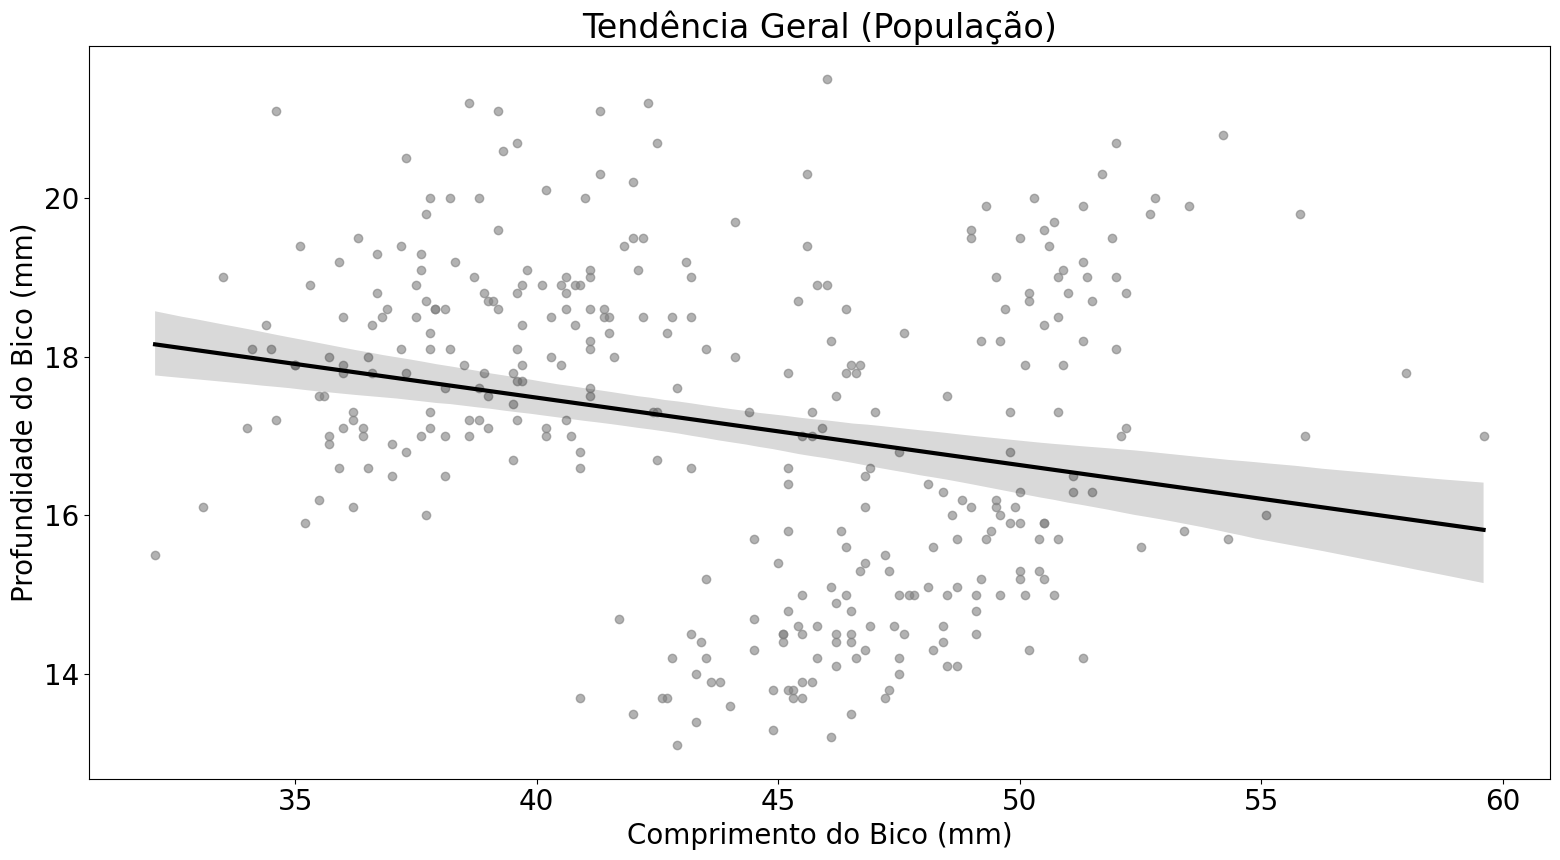

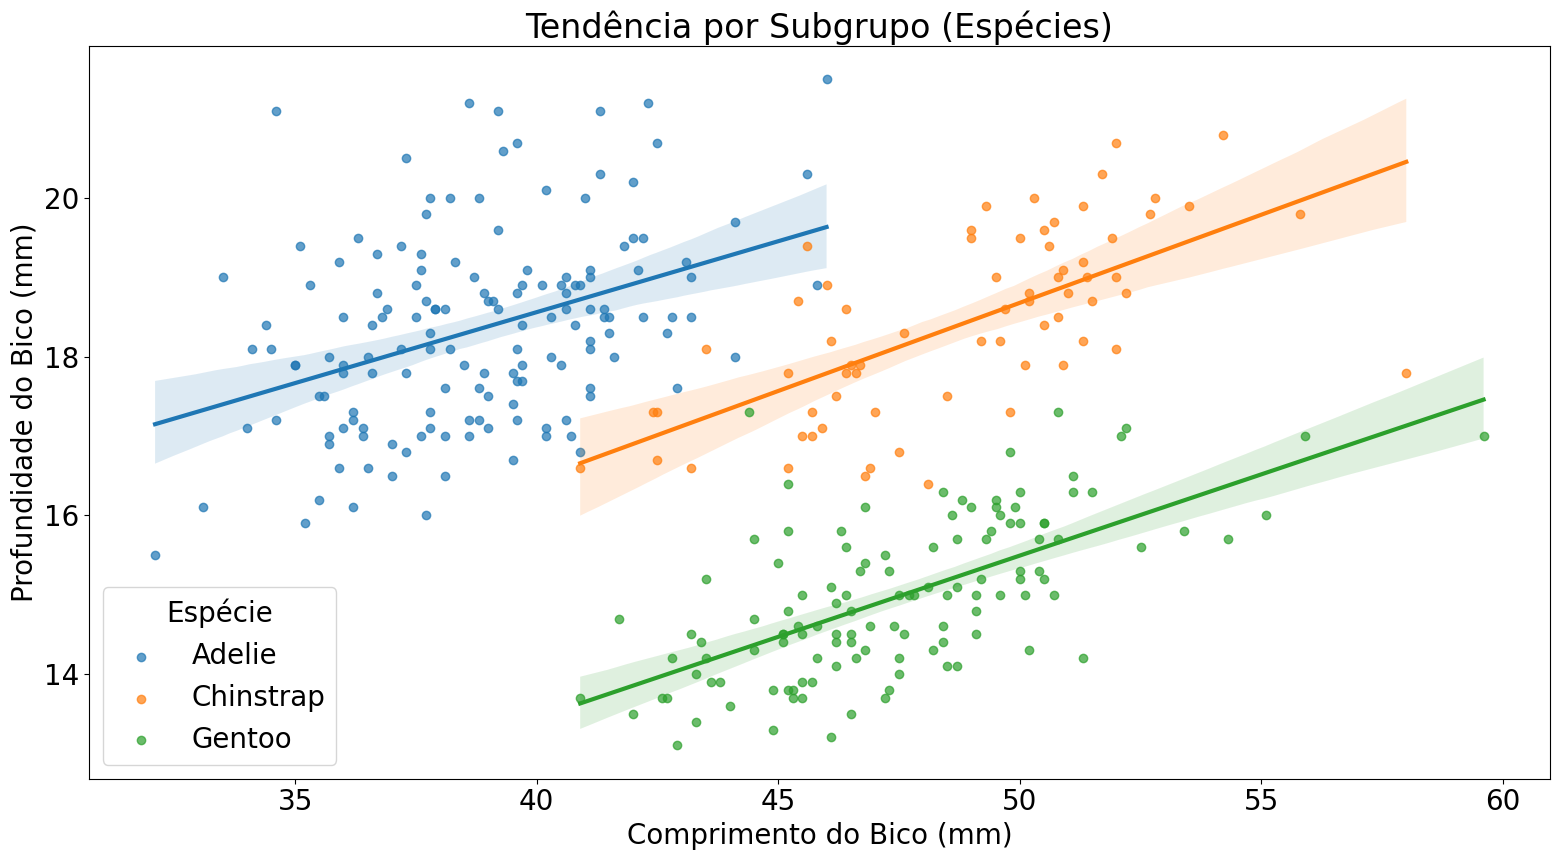

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Configuração de fonte solicitada
plt.rcParams.update({'font.size': 20})

# 1. Carregar e limpar os dados (removendo nulos para a regressão não quebrar)
df = sns.load_dataset('penguins').dropna(subset=['bill_length_mm', 'bill_depth_mm', 'species'])

# 2. Exportar o dataset para uso nas aulas da Apollo Analytics Academy
df.to_csv('palmer_penguins.csv', index=False)
print("Arquivo palmer_penguins.csv salvo com sucesso!")

# 3. Gráfico 1: População Geral (Falsa Correlação)
plt.figure(figsize=(16, 9)) # Proporção equivalente a 8:4.5 ampliada
sns.regplot(
    data=df,
    x='bill_length_mm',
    y='bill_depth_mm',
    color='gray',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'black', 'linewidth': 3}
)
plt.title('Tendência Geral (População)')
plt.xlabel('Comprimento do Bico (mm)')
plt.ylabel('Profundidade do Bico (mm)')
plt.tight_layout()
plt.show()

# 4. Gráfico 2: Subgrupos em ordem crescente (Paradoxo Revelado)
plt.figure(figsize=(16, 9))

# Garantindo a ordem alfabética crescente para as categorias
especies = sorted(df['species'].unique())
cores = ['#1f77b4', '#ff7f0e', '#2ca02c']

for esp, cor in zip(especies, cores):
    subset = df[df['species'] == esp]
    sns.regplot(
        data=subset,
        x='bill_length_mm',
        y='bill_depth_mm',
        label=esp,
        color=cor,
        scatter_kws={'alpha': 0.7},
        line_kws={'linewidth': 3}
    )

plt.title('Tendência por Subgrupo (Espécies)')
plt.xlabel('Comprimento do Bico (mm)')
plt.ylabel('Profundidade do Bico (mm)')
plt.legend(title='Espécie')
plt.tight_layout()
plt.show()

ANÁLISE ESTATÍSTICA: PINGUINS DE PALMER

[TENDÊNCIA GERAL - POPULAÇÃO]
Inclinação (Slope): -0.0850
Intercepto:         20.8855
R² (Explicabilidade):0.0552
P-valor:            1.1197e-05 (Forte falsa correlação negativa)


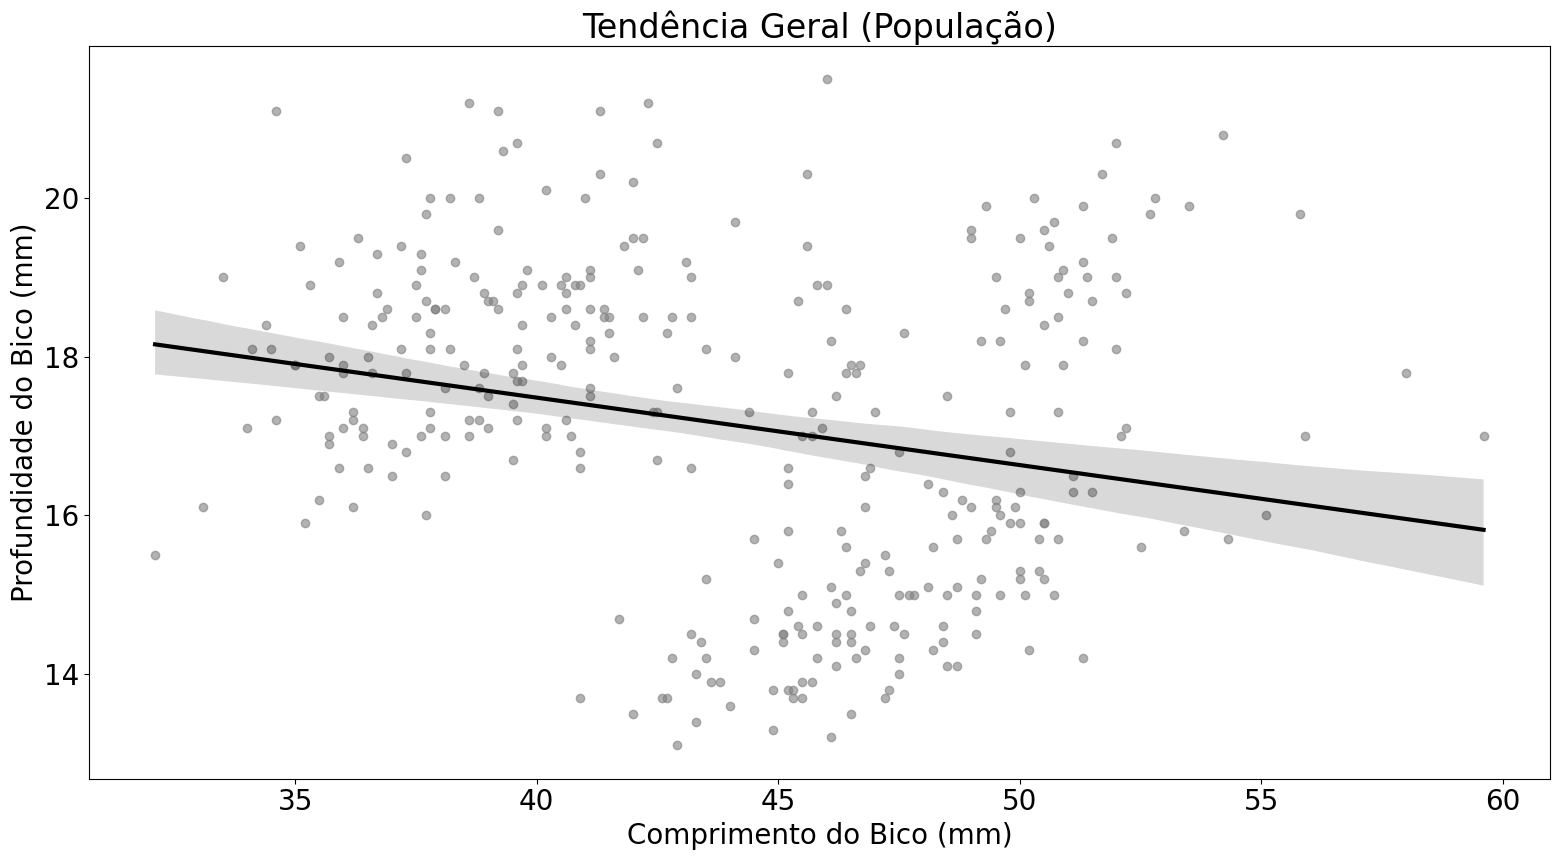


[TENDÊNCIAS POR SUBGRUPO - ESPÉCIES]

Espécie: Adelie
  Inclinação: 0.1788 (Inversão para positiva!)
  R²:         0.1533
  P-valor:    6.6741e-07

Espécie: Chinstrap
  Inclinação: 0.2222 (Inversão para positiva!)
  R²:         0.4271
  P-valor:    1.5255e-09

Espécie: Gentoo
  Inclinação: 0.2048 (Inversão para positiva!)
  R²:         0.4139
  P-valor:    1.0155e-15


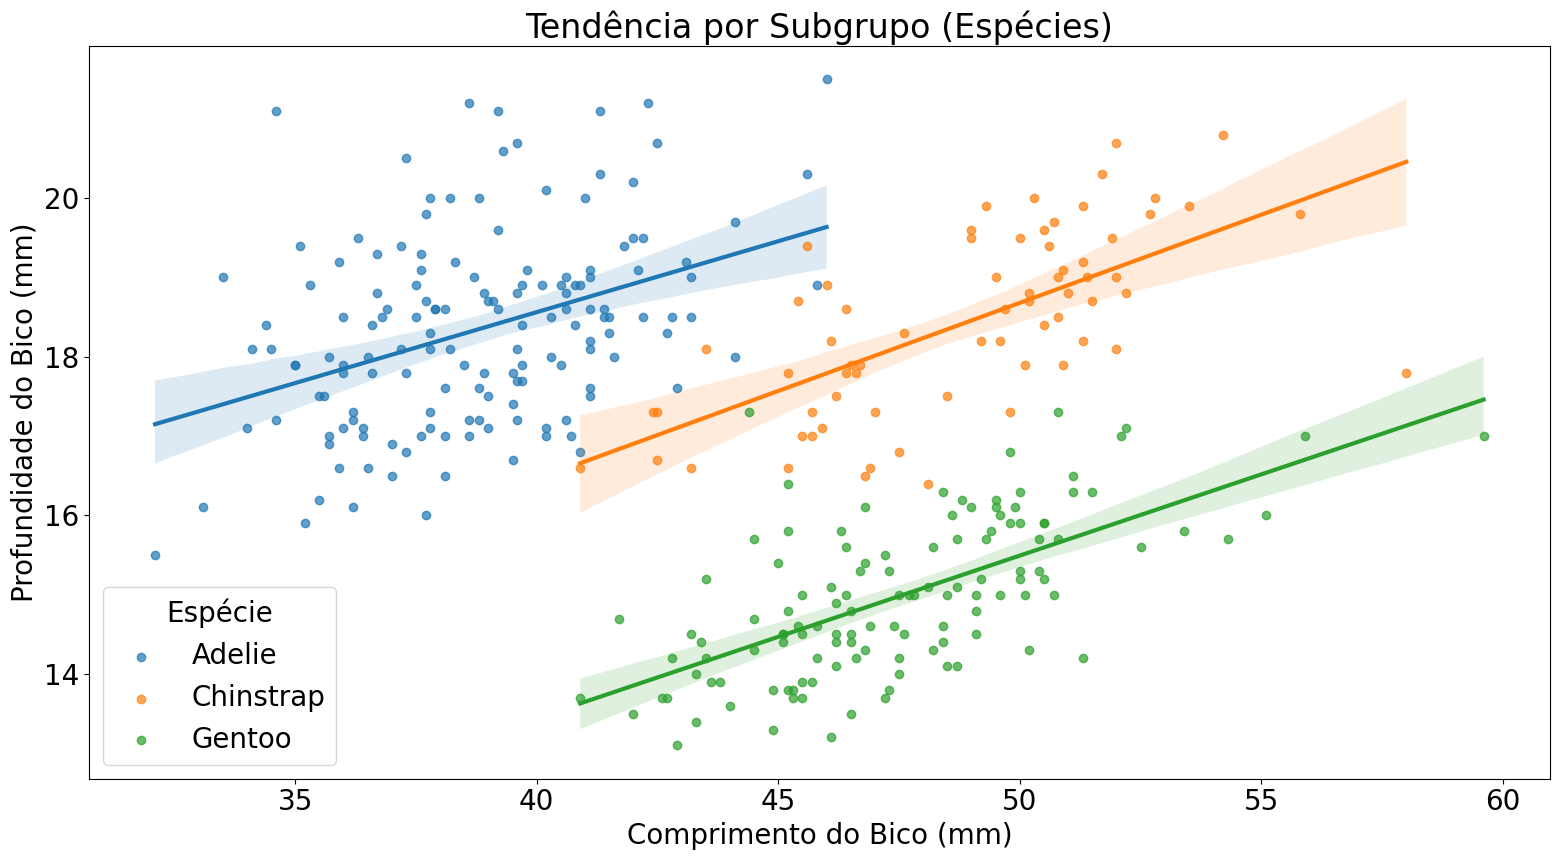

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

# Configuração visual
plt.rcParams.update({'font.size': 20})

# 1. Carregar dados
df = sns.load_dataset('penguins').dropna(subset=['bill_length_mm', 'bill_depth_mm', 'species'])
df.to_csv('palmer_penguins.csv', index=False)

print("="*50)
print("ANÁLISE ESTATÍSTICA: PINGUINS DE PALMER")
print("="*50)

# --- ESTATÍSTICAS DA POPULAÇÃO GERAL ---
reg_geral = linregress(df['bill_length_mm'], df['bill_depth_mm'])
print("\n[TENDÊNCIA GERAL - POPULAÇÃO]")
print(f"Inclinação (Slope): {reg_geral.slope:.4f}")
print(f"Intercepto:         {reg_geral.intercept:.4f}")
print(f"R² (Explicabilidade):{reg_geral.rvalue**2:.4f}")
print(f"P-valor:            {reg_geral.pvalue:.4e} (Forte falsa correlação negativa)")

# Gráfico 1: População Geral
plt.figure(figsize=(16, 9))
sns.regplot(data=df, x='bill_length_mm', y='bill_depth_mm', color='gray',
            scatter_kws={'alpha': 0.6}, line_kws={'color': 'black', 'linewidth': 3})
plt.title('Tendência Geral (População)')
plt.xlabel('Comprimento do Bico (mm)')
plt.ylabel('Profundidade do Bico (mm)')
plt.tight_layout()
plt.show()

# --- ESTATÍSTICAS POR SUBGRUPO (ORDEM CRESCENTE) ---
print("\n[TENDÊNCIAS POR SUBGRUPO - ESPÉCIES]")
especies = sorted(df['species'].unique())
cores = ['#1f77b4', '#ff7f0e', '#2ca02c']

plt.figure(figsize=(16, 9))

for esp, cor in zip(especies, cores):
    subset = df[df['species'] == esp]
    reg_sub = linregress(subset['bill_length_mm'], subset['bill_depth_mm'])

    print(f"\nEspécie: {esp}")
    print(f"  Inclinação: {reg_sub.slope:.4f} (Inversão para positiva!)")
    print(f"  R²:         {reg_sub.rvalue**2:.4f}")
    print(f"  P-valor:    {reg_sub.pvalue:.4e}")

    sns.regplot(data=subset, x='bill_length_mm', y='bill_depth_mm',
                label=esp, color=cor, scatter_kws={'alpha': 0.7},
                line_kws={'linewidth': 3})

plt.title('Tendência por Subgrupo (Espécies)')
plt.xlabel('Comprimento do Bico (mm)')
plt.ylabel('Profundidade do Bico (mm)')
plt.legend(title='Espécie')
plt.tight_layout()
plt.show()

ANÁLISE ESTATÍSTICA REAL: DATASET IRIS (FISHER, 1936)

[TENDÊNCIA GERAL - POPULAÇÃO]
Inclinação (Slope): -0.0619 (Falsa tendência negativa)
Intercepto:         3.4189
R² (Explicabilidade):0.0138
P-valor:            1.5190e-01


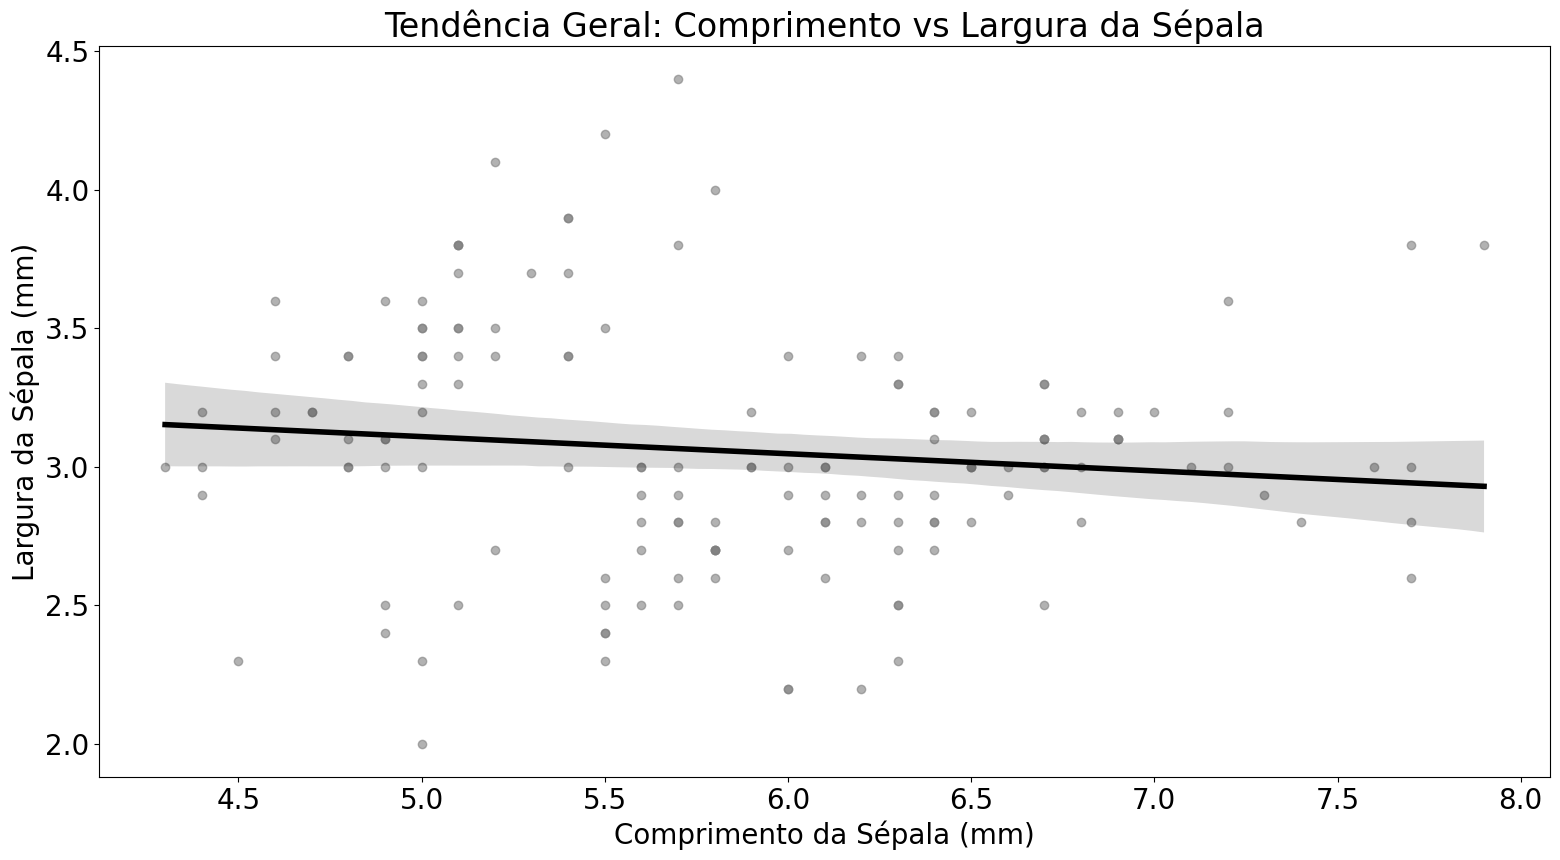


[TENDÊNCIAS POR SUBGRUPO - ESPÉCIES]

Espécie: Setosa
  Inclinação: 0.7985 (Inversão para positiva!)
  Intercepto: -0.5694
  R²:         0.5514
  P-valor:    6.7098e-10

Espécie: Versicolor
  Inclinação: 0.3197 (Inversão para positiva!)
  Intercepto: 0.8721
  R²:         0.2766
  P-valor:    8.7719e-05

Espécie: Virginica
  Inclinação: 0.2319 (Inversão para positiva!)
  Intercepto: 1.4463
  R²:         0.2091
  P-valor:    8.4346e-04


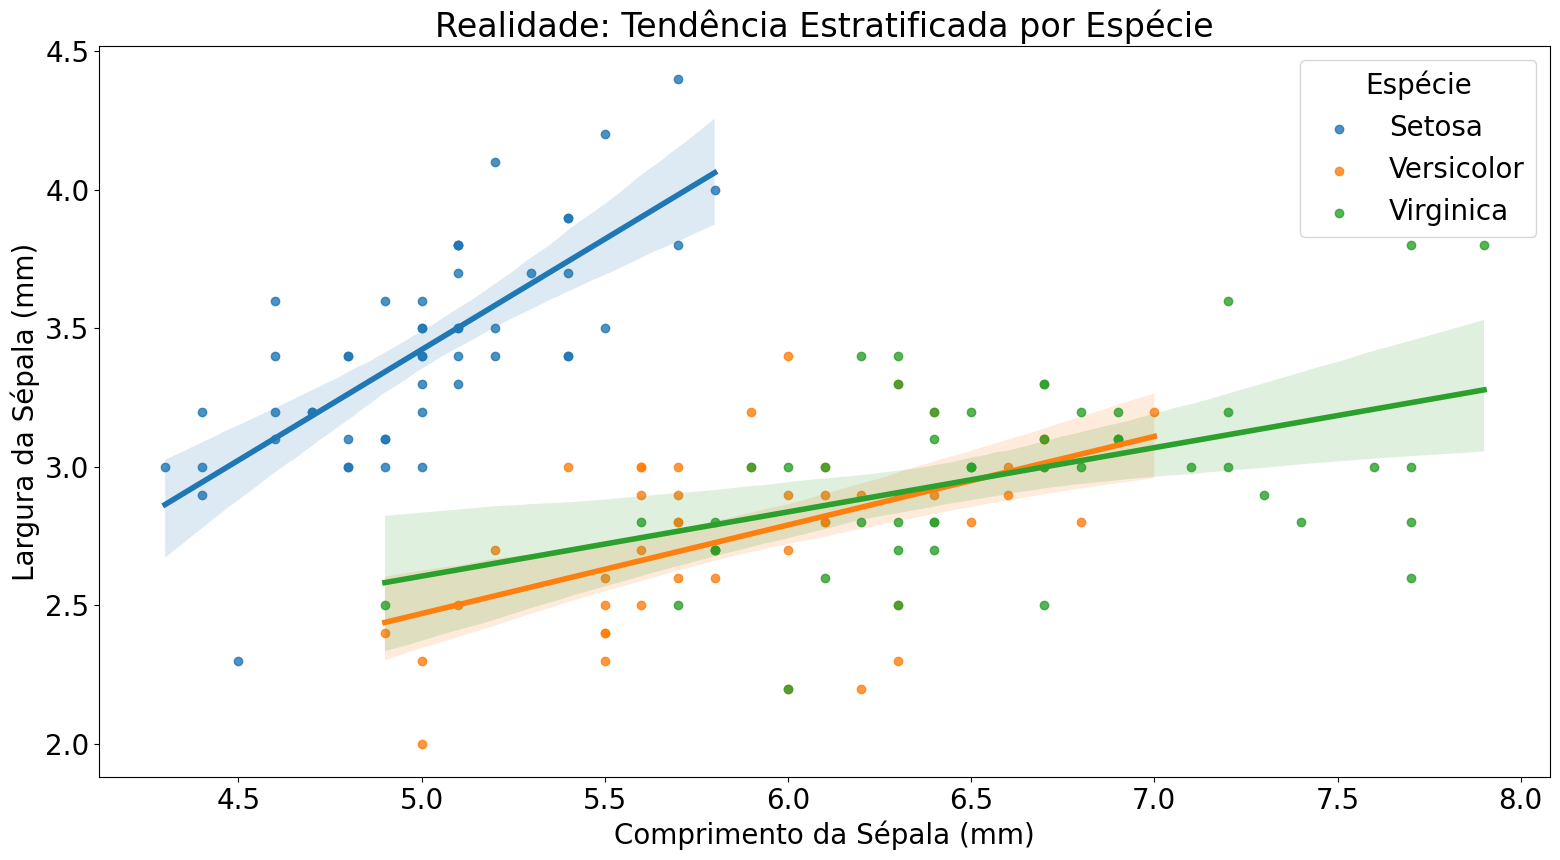

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import linregress

# Configuração visual exigida (Fonte 20)
plt.rcParams.update({'font.size': 20})

# 1. Carregando o dataset REAL de Fisher (1936)
df = sns.load_dataset('iris')

print("="*60)
print("ANÁLISE ESTATÍSTICA REAL: DATASET IRIS (FISHER, 1936)")
print("="*60)

# --- ESTATÍSTICAS DA POPULAÇÃO GERAL ---
reg_geral = linregress(df['sepal_length'], df['sepal_width'])
print("\n[TENDÊNCIA GERAL - POPULAÇÃO]")
print(f"Inclinação (Slope): {reg_geral.slope:.4f} (Falsa tendência negativa)")
print(f"Intercepto:         {reg_geral.intercept:.4f}")
print(f"R² (Explicabilidade):{reg_geral.rvalue**2:.4f}")
print(f"P-valor:            {reg_geral.pvalue:.4e}")

# Gráfico 1: População Geral (Proporção 16:9 equivalente a 8:4.5)
plt.figure(figsize=(16, 9))
sns.regplot(
    data=df,
    x='sepal_length',
    y='sepal_width',
    color='gray',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'black', 'linewidth': 4}
)
plt.title('Tendência Geral: Comprimento vs Largura da Sépala')
plt.xlabel('Comprimento da Sépala (mm)')
plt.ylabel('Largura da Sépala (mm)')
plt.tight_layout()
plt.show()

# --- ESTATÍSTICAS POR SUBGRUPO (ORDEM CRESCENTE) ---
print("\n[TENDÊNCIAS POR SUBGRUPO - ESPÉCIES]")
# Garantindo ordem alfabética: setosa, versicolor, virginica
especies = sorted(df['species'].unique())
cores = ['#1f77b4', '#ff7f0e', '#2ca02c']

plt.figure(figsize=(16, 9))

for esp, cor in zip(especies, cores):
    subset = df[df['species'] == esp]
    reg_sub = linregress(subset['sepal_length'], subset['sepal_width'])

    print(f"\nEspécie: {esp.capitalize()}")
    print(f"  Inclinação: {reg_sub.slope:.4f} (Inversão para positiva!)")
    print(f"  Intercepto: {reg_sub.intercept:.4f}")
    print(f"  R²:         {reg_sub.rvalue**2:.4f}")
    print(f"  P-valor:    {reg_sub.pvalue:.4e}")

    sns.regplot(
        data=subset,
        x='sepal_length',
        y='sepal_width',
        label=esp.capitalize(),
        color=cor,
        scatter_kws={'alpha': 0.8},
        line_kws={'linewidth': 4}
    )

plt.title('Realidade: Tendência Estratificada por Espécie')
plt.xlabel('Comprimento da Sépala (mm)')
plt.ylabel('Largura da Sépala (mm)')
plt.legend(title='Espécie')
plt.tight_layout()
plt.show()